# Pirate Treasure Hunt — Initial Team Prototype (Group 7)
**Team:** Hanbin Lee, Valerie Stapleton, Famela Dauz  
**Purpose:** Shareable first implementation for review and collaborative development.

**Proposed game rules (prototype):** A single pirate moves on a static four-direction grid. `#` denotes impassable water, `C` a coin, `M` a map, and `T` the treasure. The pirate begins with **BFS**, switches to **Greedy Best-First Search** after collecting a coin, and switches permanently to **A\*** after collecting the map. Search restarts at the current location whenever an item changes the algorithm.

This is a *working prototype*, not the final game. The grid layout, item placement, and tie-breaking behavior are illustrative and can be changed by the team. Search algorithms are independently implemented in this notebook (standard textbook algorithms), with AIMA course notebooks as conceptual references.

In [1]:
from collections import deque
from heapq import heappush, heappop
from itertools import count
from time import perf_counter
import matplotlib.pyplot as plt

GRID = [
    "S..C#.....",
    ".#..#.....",
    ".#.....M..",
    "...##..#..",
    "......#...",
    ".#..#.....",
    "....#.....",
    "..#.......",
    ".....#....",
    "...#.....T",
]
assert len(set(map(len, GRID))) == 1, 'Grid rows must have equal lengths'
assert sum(row.count('S') for row in GRID) == 1
assert sum(row.count('T') for row in GRID) == 1
HEIGHT, WIDTH = len(GRID), len(GRID[0])
START = next((r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='S')
GOAL = next((r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='T')
COINS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='C'}
MAPS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='M'}
WALLS = {(r,c) for r,row in enumerate(GRID) for c,v in enumerate(row) if v=='#'}
print('Grid:', HEIGHT, 'x', WIDTH, '| Start:', START, '| Treasure:', GOAL)
print('Coins:', sorted(COINS), '| Maps:', sorted(MAPS))

Grid: 10 x 10 | Start: (0, 0) | Treasure: (9, 9)
Coins: [(0, 3)] | Maps: [(2, 7)]


## 1. Search algorithms
All moves have cost 1. Manhattan distance is an admissible heuristic for this four-direction grid. Each algorithm returns its proposed path, the number of expanded nodes, and elapsed computation time.

In [2]:
def neighbors(position):
    r,c=position
    for dr,dc in ((-1,0),(0,1),(1,0),(0,-1)):
        nxt=(r+dr,c+dc)
        if 0 <= nxt[0] < HEIGHT and 0 <= nxt[1] < WIDTH and nxt not in WALLS:
            yield nxt

def heuristic(a,b):
    return abs(a[0]-b[0])+abs(a[1]-b[1])

def reconstruct(parent, end):
    path=[end]
    while parent[path[-1]] is not None:
        path.append(parent[path[-1]])
    return list(reversed(path))

def search(start, goal, algorithm='BFS'):
    if algorithm not in ('BFS','Greedy','A*','UCS'):
        raise ValueError('Unknown algorithm: '+algorithm)
    tick=perf_counter()
    expanded=0
    parent={start:None}
    if algorithm=='BFS':
        frontier=deque([start]); discovered={start}
        while frontier:
            current=frontier.popleft(); expanded+=1
            if current==goal:
                return {'path':reconstruct(parent,goal),'expanded':expanded,'seconds':perf_counter()-tick}
            for nxt in neighbors(current):
                if nxt not in discovered:
                    discovered.add(nxt); parent[nxt]=current; frontier.append(nxt)
    else:
        sequence=count()
        frontier=[]; best_g={start:0}; closed=set()
        def priority(node,g):
            return heuristic(node,goal) if algorithm=='Greedy' else (g if algorithm=='UCS' else g+heuristic(node,goal))
        heappush(frontier,(priority(start,0),next(sequence),start,0))
        while frontier:
            _,_,current,g=heappop(frontier)
            if current in closed or g != best_g[current]:
                continue
            closed.add(current); expanded+=1
            if current==goal:
                return {'path':reconstruct(parent,goal),'expanded':expanded,'seconds':perf_counter()-tick}
            for nxt in neighbors(current):
                ng=g+1
                if nxt not in closed and (nxt not in best_g or ng < best_g[nxt]):
                    best_g[nxt]=ng; parent[nxt]=current
                    heappush(frontier,(priority(nxt,ng),next(sequence),nxt,ng))
    raise ValueError('No route from '+str(start)+' to '+str(goal))

for algorithm in ('BFS','Greedy','A*','UCS'):
    result=search(START,GOAL,algorithm)
    print(f'{algorithm:7} | steps={len(result["path"])-1:2} | expanded={result["expanded"]:3} | time={result["seconds"]*1000:.3f} ms')

BFS     | steps=18 | expanded= 86 | time=0.124 ms
Greedy  | steps=18 | expanded= 19 | time=0.069 ms
A*      | steps=18 | expanded= 75 | time=0.176 ms
UCS     | steps=18 | expanded= 86 | time=0.132 ms


## 2. Automatic algorithm switching
The pirate follows a currently planned route. When it lands on a **new** coin or map, it switches algorithms and replans from that exact position. The map takes precedence and keeps A* active permanently. Previously collected items are not collected again.

**Important limitation:** An item must lie along the pirate's route to be collected. This first prototype does **not** force the pirate to visit all coins or the map before reaching treasure; the team can decide whether to add that rule.

In [3]:
def play_game():
    position=START; mode='BFS'; collected_coins=set(); has_map=False
    visited=[position]; switches=[]; planning=[]
    for step in range(HEIGHT*WIDTH*20):
        if position==GOAL:
            break
        plan=search(position,GOAL,mode)
        planning.append({'from':position,'algorithm':mode,'expanded':plan['expanded'],'planned_steps':len(plan['path'])-1})
        route=plan['path']
        if len(route)<2:
            raise RuntimeError('No next move')
        changed=False
        for next_position in route[1:]:
            position=next_position; visited.append(position)
            if position in MAPS and not has_map:
                has_map=True
                if mode!='A*':
                    switches.append((len(visited)-1,position,mode,'A*','map'))
                    mode='A*'; changed=True
            elif position in COINS and position not in collected_coins:
                collected_coins.add(position)
                if mode=='BFS':
                    switches.append((len(visited)-1,position,mode,'Greedy','coin'))
                    mode='Greedy'; changed=True
            if changed or position==GOAL:
                break
        if position==GOAL:
            break
        if not changed:
            raise RuntimeError('Route ended without reaching goal or switching')
    else:
        raise RuntimeError('Maximum steps exceeded')
    return {'visited':visited,'switches':switches,'planning':planning,
            'coins':collected_coins,'has_map':has_map,'final_mode':mode,
            'steps':len(visited)-1,'reached_treasure':position==GOAL}

result=play_game()
print('Reached treasure:',result['reached_treasure'])
print('Total movement steps:',result['steps'])
print('Final algorithm:',result['final_mode'])
print('Coins collected:',sorted(result['coins']),'| Map collected:',result['has_map'])
print('Algorithm switches:')
for step,position,old,new,item in result['switches']:
    print(f'  step {step}: {old} -> {new} at {position} ({item})')
print('Search plans:',len(result['planning']))

Reached treasure: True
Total movement steps: 18
Final algorithm: A*
Coins collected: [(0, 3)] | Map collected: True
Algorithm switches:
  step 3: BFS -> Greedy at (0, 3) (coin)
  step 9: Greedy -> A* at (2, 7) (map)
Search plans: 3


## 3. Visualize the grid and actual traveled route
The blue line shows the **actual sequence of moves**, not just the final planned route. The start, treasure, coin, and map positions are labeled.

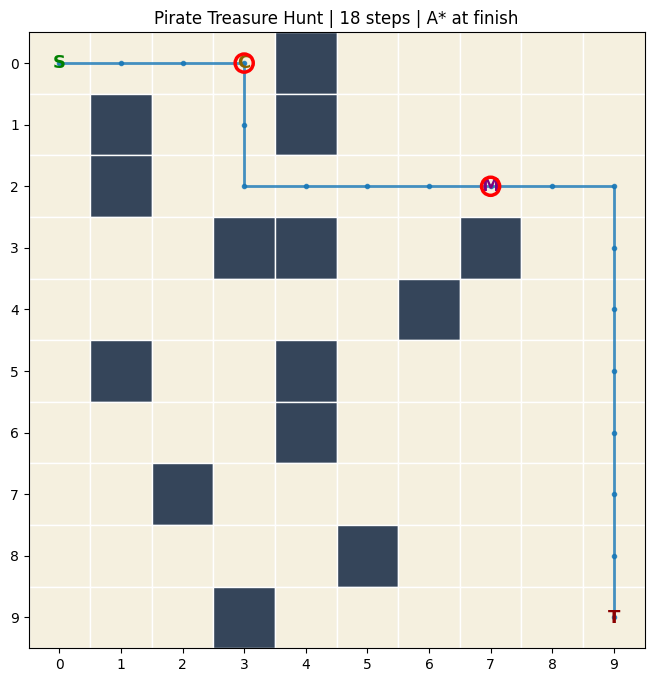

In [4]:
def draw_game(game_result):
    fig,ax=plt.subplots(figsize=(8,8))
    for r,row in enumerate(GRID):
        for c,symbol in enumerate(row):
            color='#35455a' if symbol=='#' else '#f5f0df'
            ax.add_patch(plt.Rectangle((c-.5,r-.5),1,1,facecolor=color,edgecolor='white'))
            if symbol in ('S','T','C','M'):
                ax.text(c,r,symbol,ha='center',va='center',fontsize=13,fontweight='bold',
                        color={'S':'green','T':'darkred','C':'#8a6200','M':'purple'}[symbol])
    path=game_result['visited']
    ax.plot([c for r,c in path],[r for r,c in path],'-o',color='#1677b8',lw=2,markersize=3,alpha=.8)
    for step,(r,c),old,new,item in game_result['switches']:
        ax.scatter([c],[r],s=170,facecolors='none',edgecolors='red',linewidths=2.5,zorder=5)
    ax.set_xlim(-.5,WIDTH-.5);ax.set_ylim(HEIGHT-.5,-.5)
    ax.set_xticks(range(WIDTH));ax.set_yticks(range(HEIGHT));ax.set_aspect('equal')
    ax.set_title(f'Pirate Treasure Hunt | {game_result["steps"]} steps | {game_result["final_mode"]} at finish')
    plt.show()

draw_game(result)

## 4. Baseline comparison on the same grid
Compare the same **start-to-treasure** search problem for BFS, UCS, Greedy, and A*. These are **planning** metrics, not full dynamic game-run metrics. The switching simulation is reported separately above. Time measurements vary between runs and machines.

In [5]:
baseline={name:search(START,GOAL,name) for name in ('BFS','UCS','Greedy','A*')}
print(f'{"Algorithm":<12}{"Steps":>8}{"Expanded":>12}{"Time (ms)":>14}')
for name,stats in baseline.items():
    print(f'{name:<12}{len(stats["path"])-1:>8}{stats["expanded"]:>12}{stats["seconds"]*1000:>14.3f}')
assert result['reached_treasure']
assert all(pos not in WALLS for pos in result['visited'])
assert all(heuristic(a,b)==1 for a,b in zip(result['visited'],result['visited'][1:]))
assert len(baseline['BFS']['path'])==len(baseline['UCS']['path'])==len(baseline['A*']['path'])
print('Sanity checks passed.')

Algorithm      Steps    Expanded     Time (ms)
BFS               18          86         0.092
UCS               18          86         0.316
Greedy            18          19         0.039
A*                18          75         0.107
Sanity checks passed.


## Suggested next steps for team discussion
1. Confirm the intended game rule: must the pirate collect a coin and map before the treasure, or are they optional pickups?
2. Decide whether to keep uniform movement costs or add terrain penalties. If terrain costs vary, UCS/A* comparison becomes more informative.
3. Add multiple maps, obstacles, and reproducible benchmark cases; collect metrics for the report.
4. Add a step-by-step animation or user-facing game controls if time permits.
5. Integrate with course-provided AIMA functions if the team prefers that structure, with appropriate attribution.

**Current status:** First runnable notebook with search, switching, visualization, and basic validation. Open for team review and edits.